In [ ]:
import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

print("Updated PATH to include MPI")
print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

Updated PATH to include MPI
MPI location: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin
PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



In [2]:
import os
import os.path as op
import numpy as np
import matplotlib.pyplot as plt

import hnn_core

from hnn_core import MPIBackend, JoblibBackend

import sys
sys.path.append('/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/')

from hnn_core import duecker_ET_model, simulate_dipole, jones_2009_model
from hnn_core.externals.mne import tfr_array_morlet
import matplotlib.pyplot as plt
from hnn_core.viz import plot_dipole, plot_psd, plot_tfr_morlet
import numpy as np

from scipy import signal

from alpha_beta_complex import sim_analysis_params_default, run_alpha_beta_complex_simulations, compute_psd, compute_tfr, alpha_beta_ratio


--No graphics will be displayed.


In [6]:
params = sim_analysis_params_default()
params['n_procs'] = 20
params['prox_seed'] = 1+100
params['dist_seed'] = 1+60
params['burst_std_dist'] = 15
params['fb_delay'] = 5
params['burst_std_prox'] = 15 # Jones 2009: input bursts variance = 400
params['burst_std_dist'] = 15
params['dt']=0.5
# params['weights_ampa_p'] = {'L2_basket': 0.0, 'L2_pyramidal': 5e-5, 'L5_pyramidal': 5e-5, 'L5_basket': 0.0} # proximal weights
# params['weights_ampa_d'] = {'L2_basket': 0, 'L5_pyramidal': 5e-5, 'L2_pyramidal': 5e-5} # distal weights

In [7]:
#with MPIBackend(n_procs=60, mpi_cmd='mpi_exec'):
dpl, net = run_alpha_beta_complex_simulations(params, n_trials=1)

Joblib will run 1 trial(s) in parallel by distributing trials over 20 jobs.


--No graphics will be displayed.


Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.5 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Trial 1: 360.0 ms...
Trial 1: 370.0 ms...
Trial 1: 380.0 ms...
Trial 1: 390.0 ms...
Trial 1: 400.0 ms...
Tri

In [39]:
(np.array(net.cell_response.spike_gids[0]) < 270).any()

np.False_

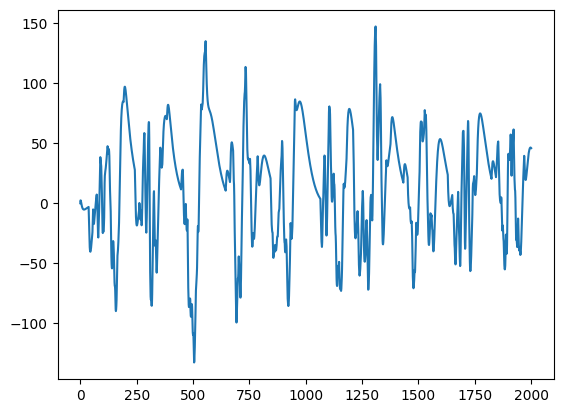

In [8]:
plt.plot(dpl[0].data['agg'])

In [22]:
f, tfr = compute_tfr(dpl)

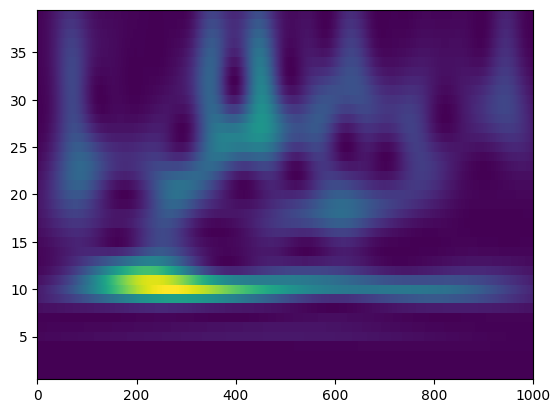

In [28]:
plt.pcolormesh(dpl[0].times, f,  tfr[0], shading='nearest')

In [10]:
params['dt'] = 0.5
with MPIBackend(n_procs=60, mpi_cmd='mpi_exec'):
    dpl, net = run_alpha_beta_complex_simulations(params, n_trials=1)

/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:909: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 1 trial(s) sequentially by distributing network neurons over 20 processes.
numprocs=20
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-c

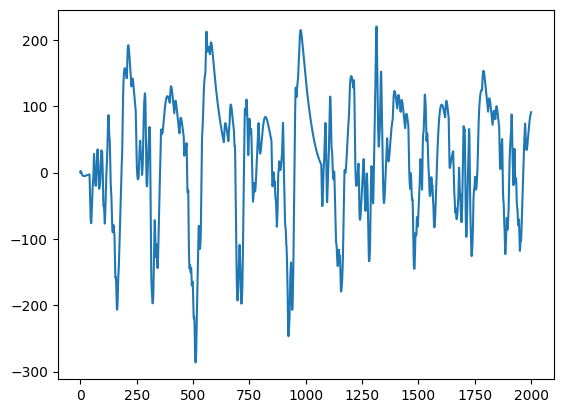

In [11]:
plt.plot(dpl[0].data['agg'])

In [32]:
class Dipole:

    def __init__(self, mat_data): 

        self.data = dict()
        self.data['agg'] = mat_data
        self.times = np.linspace(0, 1, mat_data.shape[0])
        self.nave = 1
        self.scale_applied = 1  # for visualisation
        self.sfreq = mat_data.shape[0]

In [33]:
#for s in np.arange(1,11):
import scipy.io as sio
data_pth = '/users/kduecker/SpectralEvents/data'

data = sio.loadmat(f'{data_pth}/prestim_humandetection_600hzMEG_subject{1}.mat')
n_trials = len(data['prestim_raw_yes_no'])
subj_dpls = [None]* n_trials
for trl in range(n_trials):
    data_dpl = Dipole(data['prestim_raw_yes_no'][trl])
    subj_dpls[trl] = data_dpl
    

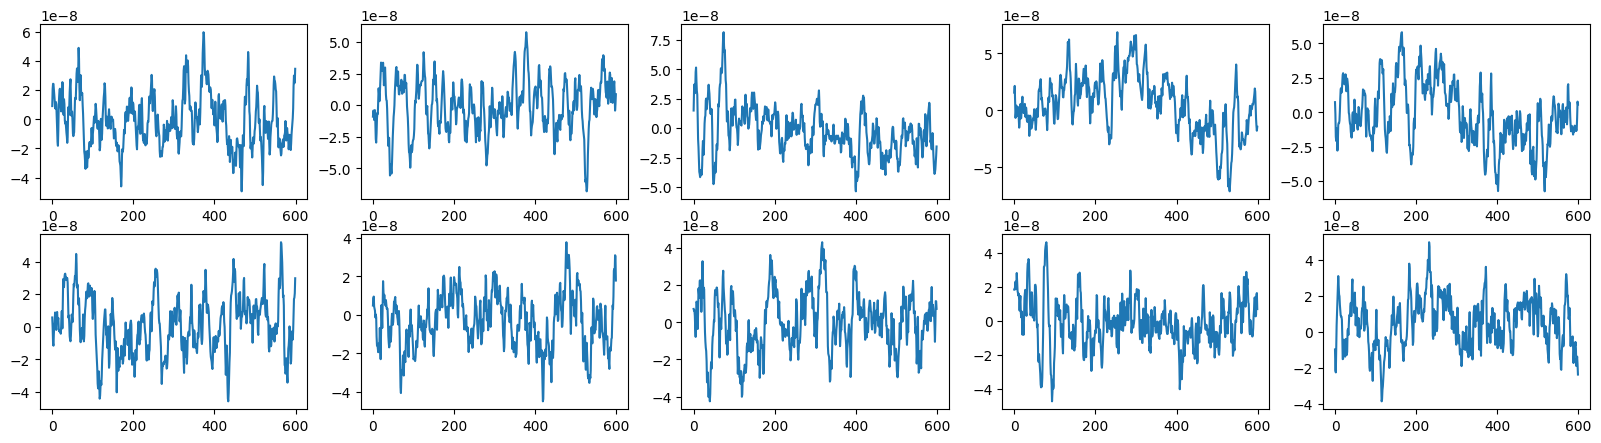

In [36]:
fig, ax = plt.subplots(2,5, figsize=(20, 5))
ax = ax.flatten()
for i, a in enumerate(ax):
    a.plot(subj_dpls[i].data["agg"])

(0.0, 60.0)

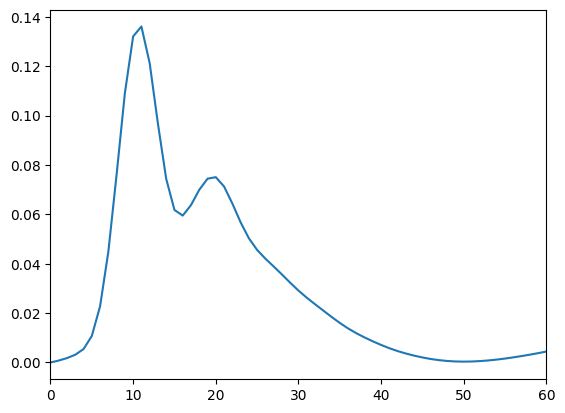

In [6]:
f, psd = compute_psd(params, dpl)
plt.plot(f[0], psd.mean(axis=0))

plt.xlim([0, 60])

# tfr = compute_tfr(dpl)

# fig, ax = plt.subplots(2,5, figsize=(20,5))
# ax = ax.flatten()
# for i, a in enumerate(ax):
#     a.pcolormesh(dpl[0].times, tfr[0], tfr[1][i], shading='nearest')

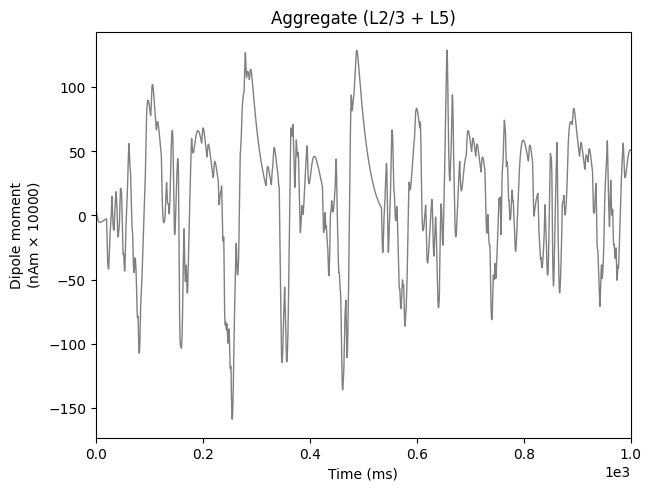

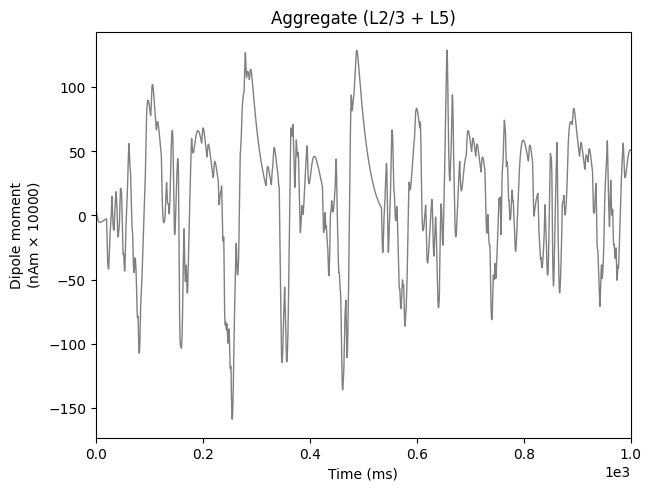

In [7]:
dpl[0].plot()

In [8]:
ar, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(dpl)

In [9]:
np.mean(ar), np.median(ar)

(np.float32(1.7689748), np.float32(1.6794105))

In [10]:
prob_overlap

0.3373493975903614

/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:909: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 30 trial(s) sequentially by distributing network neurons over 64 processes.
numprocs=64
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.soLoading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-c

(0.0, 60.0)

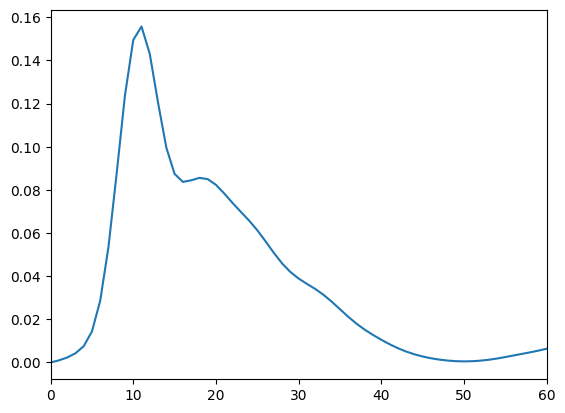

In [68]:
params['fb_delay'] = 4.
dpl, net = run_alpha_beta_complex_simulations(params, n_trials=30)

f, psd = compute_psd(params, dpl)
plt.plot(f[0], psd.mean(axis=0))
plt.xlim([0, 60])

# tfr = compute_tfr(dpl)

# fig, ax = plt.subplots(2,5, figsize=(20,5))
# ax = ax.flatten()
# for i, a in enumerate(ax):
#     a.pcolormesh(dpl[0].times, tfr[0], tfr[1][i], shading='nearest')

In [69]:
ar, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(dpl)

In [70]:
np.mean(ar), np.median(ar)

(np.float32(1.7132725), np.float32(1.6987987))

In [71]:
prob_overlap

0.5

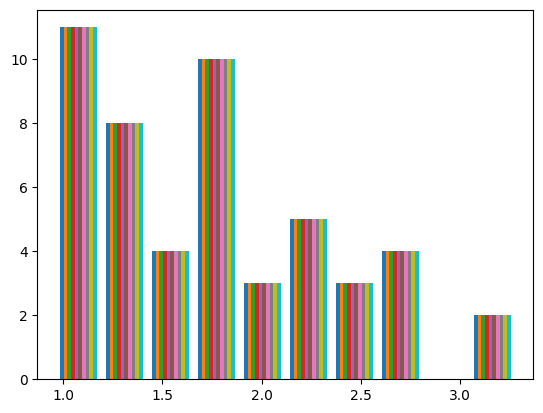

In [16]:
plt.hist(ar);

In [17]:
np.mean(ar), np.median(ar), prob_overlap

(np.float32(1.7656863), np.float32(1.7194438), 0.43373493975903615)

In [ ]:
params['fb_delay'] = 0
params['burst_std_dist'] = 20
dpl, net = run_alpha_beta_complex_simulations(params, n_trials=50)

f, psd = compute_psd(params, dpl)
plt.plot(f[0], psd.mean(axis=0))
plt.xlim([0, 60])

tfr = compute_tfr(dpl)

fig, ax = plt.subplots(2,5, figsize=(20,5))
ax = ax.flatten()
for i, a in enumerate(ax):
    a.pcolormesh(dpl[0].times, tfr[0], tfr[1][i], shading='nearest')

/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:912: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 50 trial(s) sequentially by distributing network neurons over 64 processes.
numprocs=64
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/l

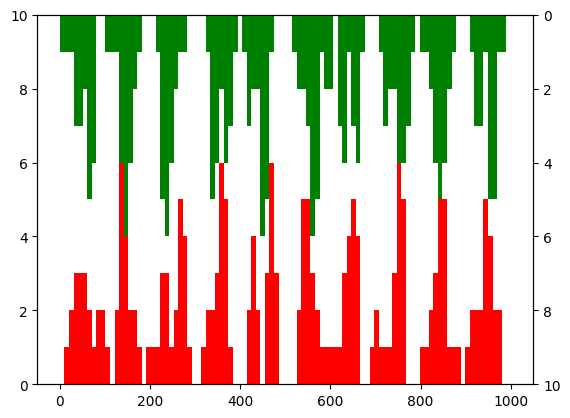

In [29]:
spike_prox = np.array(net.cell_response.spike_times_by_type['prox'][0]).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['dist'][0]).reshape(-1,1)

bins = np.linspace(0, 1000, 100)
fig, ax = plt.subplots()

ax.hist(spike_prox, bins, color='r')
ax.set_ylim([0, 10])
ax1tw = ax.twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 10])
ax1tw.invert_yaxis()

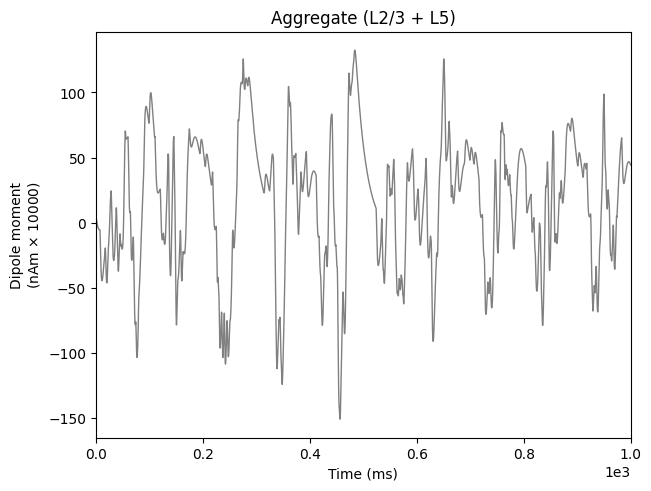

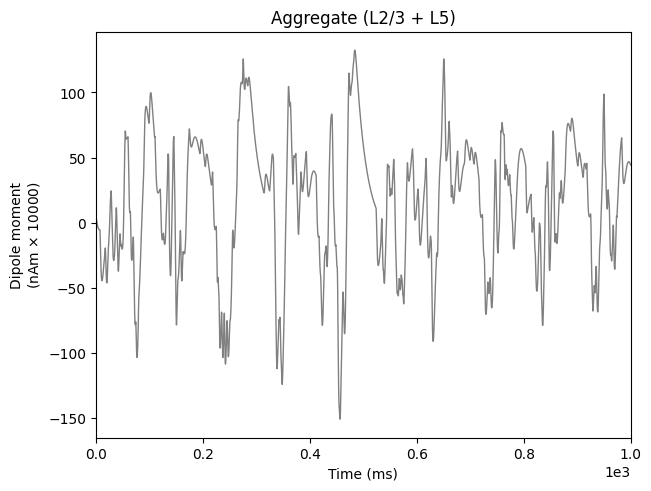

In [20]:
dpl[0].plot()

In [16]:
ar, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(dpl)

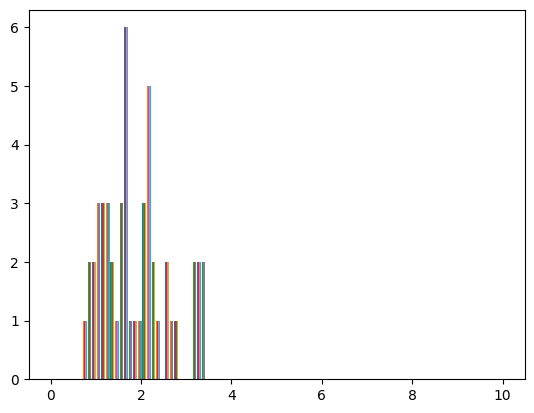

In [17]:
plt.hist(ar, bins=np.linspace(0,10,100));

In [18]:
prob_overlap

0.30120481927710846

In [19]:
np.mean(ar), np.median(ar)

(np.float32(1.8677927), np.float32(1.7144617))